# Example 1: estimating the killing rate $c_T$

Notebook version of `ex1_cT.py` (same code, split by steps).

```text
 Mini-course: Adaptive observers for immune digital twins
 EXAMPLE 1 -- Estimate ONE parameter: the T-cell killing rate c_T
             (and reconstruct the unmeasured CD8+ T cells)
 Based on: Rodriguez-Linan, Sereno, Quiroz-Compean, Hernandez-Vargas,
           "Adaptive Observers for Calibrating Immune Digital Twins in
            Viral Infections", IEEE CDC 2025.  Eqs. (1)-(2), (13)-(17).
 This code is written to be READ, not to be fast. Every step is explicit.
 The in-host model (Eqs. 1-2):
     dV/dt = p V (1 - V/K) - c_T V T - c V
     dT/dt = S_T + r T G(V) - delta_T T,      G(V) = V^m / (V^m + k_T^m)
 Change of coordinates (Eq. 13):  x1 = V/lambda,  x2 = (dV/dt)/lambda
 Measured outputs:                y1 = x1,        y2 = x2   (so C = I)
 State-affine form (Eq. 15):      dx/dt = A(y) x + beta(y) + phi(y) theta
                                  y     = C x
 In this example the only unknown is   theta = gamma = c_T * S_T
 (we estimate gamma ~ 0.19 instead of c_T ~ 2e-6 because numbers of
  order 1 are much friendlier for the solver; then c_T = gamma / S_T).
```

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
%matplotlib inline

### Step 1. Parameters of the virtual patient ("Mean" patient of Hernandez-Vargas & Velasco-Hernandez, Annu. Rev. Control 2020)

In [2]:
p     = 8.57      # virus replication rate                 [1/day]
K     = 2.35e9    # carrying capacity of the virus         [copies/ml]
c     = 2.4       # viral clearance rate                   [1/day]
c_T   = 1.89e-6   # killing rate of virus by T cells       <-- UNKNOWN
delta_T = 0.1     # death rate of T cells                  [1/day]
k_T   = 1.26e5    # half-saturation constant of T cells
m     = 2         # Hill coefficient (dimensionless)
r     = 0.194     # T-cell activation/proliferation rate   [1/day]
T0    = 1e6       # initial number of T cells
S_T   = delta_T * T0   # homeostatic replenishment rate (= 1e5)
V0    = 0.31      # initial viral load at t = -3 days

# Lumped parameters used in the paper
alpha = p - c          # net viral growth rate
sigma = p / K          # logistic term
gamma = c_T * S_T      # <-- the parameter our observer will estimate (theta)

lam = 1e8              # scaling factor lambda (V is huge, so we work with V/lambda)

### Step 2. The in-host model (Eqs. 1-2): this is our "virtual patient"

In [3]:
def G(V):
    """T-cell activation function G(V) = V^m / (V^m + k_T^m)."""
    return V**m / (V**m + k_T**m)


def patient(t, V, T):
    """Right-hand side of Eqs. (1)-(2). Returns dV/dt and dT/dt."""
    dV = p * V * (1 - V / K) - c_T * V * T - c * V
    dT = S_T + r * T * G(V) - delta_T * T
    return dV, dT

### Step 3. Before symptoms (t = -3 ... 0 days) there are NO measurements.

We only simulate the patient to know the state at t = 0.

In [4]:
t_start, t_obs, t_end = -3.0, 0.0, 21.0

pre = solve_ivp(lambda t, z: patient(t, z[0], z[1]),
                [t_start, t_obs], [V0, T0], rtol=1e-8, atol=1e-8)
V_at_0 = pre.y[0, -1]
T_at_0 = pre.y[1, -1]
print(f"At t = {t_obs:g} (first measurement): V = {V_at_0:.3e}, T = {T_at_0:.3e}")

At t = 0 (first measurement): V = 1.164e+05, T = 1.014e+06


### Step 4. Measurements y1 = V/lambda and y2 = (dV/dt)/lambda Optional: multiplicative noise on the viral load, V_meas = V*eta, eta ~ N(1, NOISE_LEVEL), held constant during each hour.

In [5]:
ADD_NOISE   = False   # <-- set to True for the noise exercise
NOISE_LEVEL = 0.05    # 0.05 = 5 %, 0.10 = 10 %, ...

rng = np.random.default_rng(seed=1)
t_noise = np.arange(t_obs, t_end + 1, 1 / 24)            # one value per hour
eta     = 1 + NOISE_LEVEL * rng.standard_normal(t_noise.size)


def measurements(t, V, T):
    """What the clinic gives us: viral load and its time derivative (scaled)."""
    dV, _ = patient(t, V, T)
    V_meas = V
    if ADD_NOISE:
        k = int((t - t_obs) * 24)                          # index of current hour
        V_meas = V * eta[k]
    y1 = V_meas / lam
    y2 = dV / lam
    return y1, y2

### Step 5. State-affine form (Eq. 15) for EXAMPLE 1.

```text
  In the new coordinates (Eq. 14):
    dx1/dt = x2
    dx2/dt = x2^2/x1 + (alpha*delta_T - gamma) x1 - lambda*delta_T*sigma x1^2
             - r*alpha*x1*G + lambda*r*sigma*x1^2*G
             - delta_T x2 - lambda*sigma x1 x2 + r x2 G

  Recipe:  (i)  terms with the unknown gamma          -> phi(y) * theta
           (ii) terms (known coeff.(y)) * x1 or * x2   -> A(y) x
           (iii) terms that only depend on y           -> beta(y)
  Every entry may depend ONLY on measured signals y1, y2 (never on T!).
```

In [6]:
def state_affine_matrices(y1, y2):
    Gy = G(lam * y1)                                       # G evaluated with the measured V

    a21 = alpha * (delta_T - r * Gy) + lam * sigma * y1 * (r * Gy - delta_T)
    a22 = r * Gy - lam * sigma * y1 - delta_T

    A = np.array([[0.0, 1.0],
                  [a21, a22]])

    beta = np.array([[0.0],
                     [y2**2 / y1]])

    phi = np.array([[0.0],
                    [-y1]])                                # theta = gamma enters as -gamma*x1

    C = np.eye(2)                                          # we measure both x1 and x2
    return A, beta, phi, C

### Step 6. Observer tuning knobs (Eq. 17)

In [7]:
rho_x     = 100.0       # forgetting factor for S      (large = fast state correction)
rho_theta = 4.0         # forgetting factor for Gamma  (large = fast parameter adaptation)
Q         = np.eye(2)   # weight on the output error

### Step 7. Patient + adaptive observer in ONE ODE system (Eq. 17)

```text
  Layout of the big state vector z (11 entries):
    z[0]  V          z[1]  T            <- virtual patient (unknown to observer)
    z[2]  x1_hat     z[3]  x2_hat       <- estimated states
    z[4]  S11        z[5]  S12   z[6] S22   <- symmetric matrix S (2x2)
    z[7]  Lambda1    z[8]  Lambda2      <- Lambda (2x1)
    z[9]  Gamma                         <- Gamma  (1x1)
    z[10] gamma_hat                     <- theta_hat (1x1)
```

In [8]:
def patient_and_observer(t, z):
    # --- unpack ----------------------------------------------------------
    V, T      = z[0], z[1]
    x_hat     = np.array([[z[2]], [z[3]]])
    S         = np.array([[z[4], z[5]],
                          [z[5], z[6]]])
    Lambda    = np.array([[z[7]], [z[8]]])
    Gamma     = np.array([[z[9]]])
    theta_hat = np.array([[z[10]]])

    # --- the patient evolves (in real life this is the real person) -----
    dV, dT = patient(t, V, T)

    # --- the clinic measures V and dV/dt --------------------------------
    y1, y2 = measurements(t, V, T)
    y = np.array([[y1], [y2]])

    # --- matrices of the state-affine form, built from MEASURED data ----
    A, beta, phi, C = state_affine_matrices(y1, y2)

    # --- adaptive observer, Eq. (17) ------------------------------------
    S_inv     = np.linalg.inv(S)
    Gamma_inv = np.linalg.inv(Gamma)
    error     = y - C @ x_hat                              # output estimation error

    dx_hat     = A @ x_hat + beta + phi @ theta_hat \
                 + (S_inv @ C.T + Lambda @ Gamma_inv @ Lambda.T @ C.T) @ Q @ error
    dS         = -rho_x * S - A.T @ S - S @ A + C.T @ Q @ C
    dLambda    = (A - S_inv @ C.T @ Q @ C) @ Lambda + phi
    dGamma     = -rho_theta * Gamma + Lambda.T @ C.T @ Q @ C @ Lambda
    dtheta_hat = Gamma_inv @ Lambda.T @ C.T @ Q @ error

    # --- pack (same order as z) -----------------------------------------
    return [dV, dT,
            dx_hat[0, 0], dx_hat[1, 0],
            dS[0, 0], dS[0, 1], dS[1, 1],
            dLambda[0, 0], dLambda[1, 0],
            dGamma[0, 0],
            dtheta_hat[0, 0]]

### Step 8. Initial conditions of the observer (we do NOT know the truth!)

In [9]:
y1_0, y2_0 = measurements(t_obs, V_at_0, T_at_0)

x_hat_0     = [0.5 * y1_0, 0.5 * y2_0]   # a wrong guess of the states (50 % off)
S_0         = [1.0, 0.0, 1.0]            # S(0) = I      -> S11, S12, S22
Lambda_0    = [0.0, 0.0]                 # Lambda(0) = 0
Gamma_0     = [1.0]                      # Gamma(0) = 1
gamma_hat_0 = [0.05]                     # initial guess of gamma (true value 0.189)

z0 = [V_at_0, T_at_0] + x_hat_0 + S_0 + Lambda_0 + Gamma_0 + gamma_hat_0

### Step 9. Solve

In [10]:
t_eval = np.linspace(t_obs, t_end, 2001)
sol = solve_ivp(patient_and_observer, [t_obs, t_end], z0, t_eval=t_eval,
                rtol=1e-6, atol=1e-9, max_step=1 / 24)
print(sol.message)

t         = sol.t
V         = sol.y[0]
T         = sol.y[1]
V_hat     = lam * sol.y[2]            # back to original units
dV_hat    = lam * sol.y[3]
gamma_hat = sol.y[10]

The solver successfully reached the end of the integration interval.


### Step 10. Back to the physical parameters and the unmeasured state T

```text
  c_T = gamma / S_T                    (S_T known)
  From Eq. (1):  c_T T = alpha - sigma V - (dV/dt)/V
           =>    T_hat = (alpha - sigma V_hat - dV_hat/V_hat) / c_T_hat
```

In [11]:
c_T_hat = gamma_hat / S_T
c_T_hat_safe = np.where(c_T_hat > 0, c_T_hat, np.nan)  # T_hat undefined if c_T_hat <= 0
T_hat = (alpha - sigma * V_hat - dV_hat / V_hat) / c_T_hat_safe

print(f"True  c_T = {c_T:.4e}")
print(f"Final c_T_hat = {c_T_hat[-1]:.4e}  (relative error {abs(c_T_hat[-1] - c_T) / c_T * 100:.2f} %)")
for day in [2, 4, 6, 8]:
    k = np.argmin(abs(t - day))
    print(f"  day {day:2d}: c_T_hat = {c_T_hat[k]:.3e}")

True  c_T = 1.8900e-06
Final c_T_hat = 1.8900e-06  (relative error 0.00 %)
  day  2: c_T_hat = 6.625e-07
  day  4: c_T_hat = 1.890e-06
  day  6: c_T_hat = 1.890e-06
  day  8: c_T_hat = 1.890e-06


### Step 11. Persistent-excitation (PE) meter

```text
  PE condition (Aranovskiy et al. 2017, Eq. 4), written for our observer:
      lambda_min( integral_t^{t+T}  Lambda' C' Q C Lambda ds ) >= delta > 0
  Gamma(t) is exactly this integral with exponential forgetting:
      Gamma(t) = e^{-rho_theta t} Gamma(0) + int_0^t e^{-rho_theta (t-s)} Lambda' C' Q C Lambda ds
  so lambda_min(Gamma(t)) tells us ONLINE how much information we have.
  Here q = 1, so Gamma is a scalar and lambda_min(Gamma) = Gamma.
  Reference: pure forgetting e^{-rho_theta t} Gamma(0) = "no new information".
```

In [12]:
lam_min_Gamma = sol.y[9]                                   # Gamma (1x1)
no_info = np.exp(-rho_theta * (t - t_obs)) * Gamma_0[0]    # what Gamma would be with Lambda = 0

### Step 12. Plots

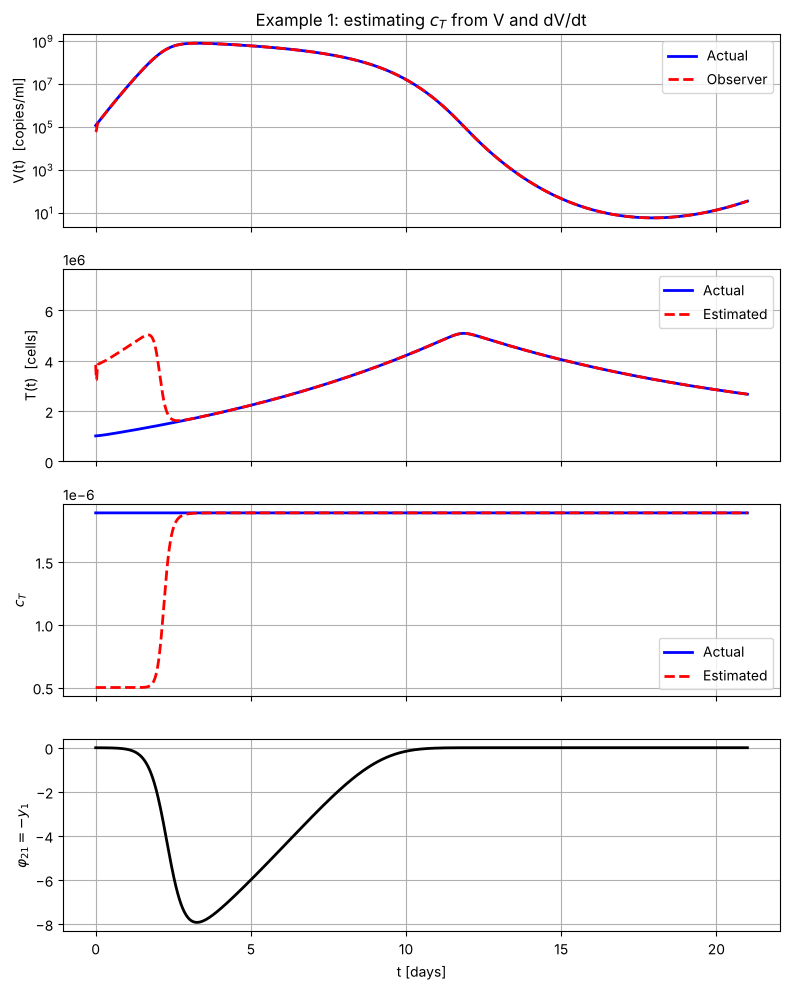

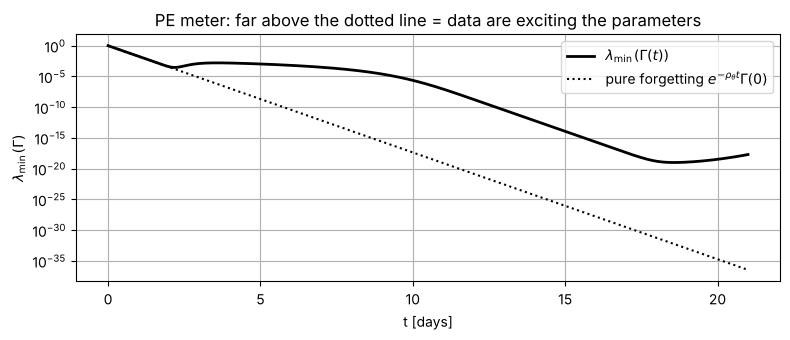

In [13]:
fig, ax = plt.subplots(4, 1, figsize=(8, 10), sharex=True)

ax[0].semilogy(t, V, 'b-', lw=2, label='Actual')
ax[0].semilogy(t, V_hat, 'r--', lw=2, label='Observer')
ax[0].set_ylabel('V(t)  [copies/ml]')
ax[0].legend()
ax[0].set_title('Example 1: estimating $c_T$ from V and dV/dt')

ax[1].plot(t, T, 'b-', lw=2, label='Actual')
ax[1].plot(t, T_hat, 'r--', lw=2, label='Estimated')
ax[1].set_ylabel('T(t)  [cells]')
ax[1].set_ylim(0, 1.5 * T.max())
ax[1].legend()

ax[2].plot(t, c_T * np.ones_like(t), 'b-', lw=2, label='Actual')
ax[2].plot(t, c_T_hat, 'r--', lw=2, label='Estimated')
ax[2].set_ylabel('$c_T$')
ax[2].legend()

# Persistent excitation: the regressor phi_21 = -y1 must "move" to learn theta
ax[3].plot(t, -V / lam, 'k-', lw=2)
ax[3].set_ylabel(r'$\varphi_{21} = -y_1$')
ax[3].set_xlabel('t [days]')

for a in ax:
    a.grid(True)
plt.tight_layout()
plt.show()

# --- PE meter -------------------------------------------------------------
plt.figure(figsize=(8, 3.5))
plt.semilogy(t, lam_min_Gamma, 'k-', lw=2, label=r'$\lambda_{\min}(\Gamma(t))$')
plt.semilogy(t, no_info, 'k:', lw=1.5, label=r'pure forgetting $e^{-\rho_\theta t}\Gamma(0)$')
plt.xlabel('t [days]')
plt.ylabel(r'$\lambda_{\min}(\Gamma)$')
plt.title('PE meter: far above the dotted line = data are exciting the parameters')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()